# 问题 1：影响力网络（v2）

在 v1 基础上修正三处：

1. **PageRank 补回悬空节点权重**：原版把出度为 0 的节点 `outdeg=1` 只避免除零，但这些节点每轮会流失权重，导致分数总和不等于 1。v2 把悬空节点的权重按均匀分布重新注入。
2. **`reach3` 改用布尔可达矩阵**：原版 `int8` 矩阵乘法会先「数路径」再转布尔，路径数 ≥256 时溢出为 0，漏掉可达节点；且环路会把节点自己算进去。v2 用 `bool` 矩阵做可达累积并 `setdiag(False)` 排除自己。
3. **区分 `DIG` 与跨流派比例**：`DIG` 是「直接追随者覆盖多少流派」（覆盖广度）；新增 `cross_genre_ratio` = 跨流派直接追随者数 / 流派已知的直接追随者数（跨流派影响）。

指标语义见后文对照表。

In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
from scipy.sparse import csgraph
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100

edges = pd.read_csv('output/edges.csv', dtype=str)
artists = pd.read_csv('output/artists.csv', dtype=str)

# 统一流派里的 nan/空为 Unknown
for g in ['influencer_main_genre', 'follower_main_genre']:
    edges[g] = edges[g].replace({'nan': 'Unknown', '': 'Unknown', 'None': 'Unknown'})

print('edges:', edges.shape, '| artists:', artists.shape)

edges: (42770, 8) | artists: (5854, 18)


In [2]:
# 建图：A[i,j]=1 表示 i 影响 j（influencer i → follower j）
all_ids = np.unique(np.concatenate([edges['influencer_id'].values, edges['follower_id'].values]))
node2idx = {n: i for i, n in enumerate(all_ids)}
n = len(all_ids)

row = edges['influencer_id'].map(node2idx).values
col = edges['follower_id'].map(node2idx).values
A = sp.csr_matrix((np.ones(len(edges)), (row, col)), shape=(n, n))

m = A.nnz
density = m / (n * (n - 1))
bidir = (A.multiply(A.T)).nnz // 2
n_comp, labels = csgraph.connected_components(A + A.T, directed=False)

print(f'节点 n={n}  边 m={m}  密度={density:.5f}')
print(f'双向边(2-环)={bidir}  无向连通分量={n_comp}  最大连通分量={np.bincount(labels).max()}/{n}')

节点 n=5603  边 m=42770  密度=0.00136
双向边(2-环)=39  无向连通分量=3  最大连通分量=5599/5603


## 修正后的两个函数

In [3]:
def pagerank(A, alpha=0.85, tol=1e-8, max_iter=200):
    # A[i,j]=1 表示 i→j；返回沿边累积的 PageRank（悬空节点权重补回）
    A = sp.csr_matrix(A, dtype=float)
    n = A.shape[0]
    if n == 0:
        return np.empty(0, dtype=float)

    out_degree = np.asarray(A.sum(axis=1)).ravel()
    dangling = out_degree == 0
    inv_out = np.divide(1.0, out_degree, out=np.zeros_like(out_degree), where=~dangling)

    AT = A.T.tocsr()
    r = np.full(n, 1.0 / n)

    for _ in range(max_iter):
        base = (1.0 - alpha + alpha * r[dangling].sum()) / n
        r_new = alpha * (AT @ (r * inv_out)) + base
        if np.abs(r_new - r).sum() < tol:
            return r_new
        r = r_new

    raise RuntimeError('PageRank 未在 max_iter 次内收敛')


def reach_within_k(A, k=3):
    # 每个节点 1..k 跳内能到达的其他节点数（布尔可达，排除自己）
    adjacency = sp.csr_matrix(A, dtype=bool, copy=True)
    adjacency.eliminate_zeros()
    reach = sp.csr_matrix(adjacency.shape, dtype=bool)
    current = adjacency

    for step in range(k):
        if step > 0:
            current = current @ adjacency
        reach = reach.maximum(current)

    reach.setdiag(False)
    reach.eliminate_zeros()
    return np.diff(reach.indptr)

## 计算指标（含 PageRank 质量守恒验证）

In [4]:
outdeg = np.asarray(A.sum(axis=1)).ravel()
indeg = np.asarray(A.sum(axis=0)).ravel()
pr_source = pagerank(A.T)   # 反向图 → 源头影响力
pr_sink   = pagerank(A)     # 原图   → 被影响力
reach3    = reach_within_k(A, 3)

# 验证：修正后分数总和应 = 1（质量守恒）
print(f'pr_source.sum() = {pr_source.sum():.8f}  (应 ≈ 1)')
print(f'pr_sink.sum()   = {pr_sink.sum():.8f}  (应 ≈ 1)')

# DIG：直接追随者覆盖多少流派（覆盖广度）
dig = edges.groupby('influencer_id')['follower_main_genre'].nunique()

# 跨流派追随者比例：不同于影响者自身流派的直接追随者数 / 流派已知的直接追随者数
inf_genre_map = artists.set_index('artist_id')['genre']
e2 = edges.copy()
e2['inf_genre'] = e2['influencer_id'].map(inf_genre_map).fillna('Unknown')
known = (e2['inf_genre'] != 'Unknown') & (e2['follower_main_genre'] != 'Unknown')
e_known = e2[known].copy()
e_known['cross'] = (e_known['follower_main_genre'] != e_known['inf_genre']).astype(int)
cross_ratio = e_known.groupby('influencer_id')['cross'].mean()

df = pd.DataFrame({
    'out_degree': outdeg,
    'in_degree': indeg,
    'pagerank_source': pr_source,
    'pagerank_sink': pr_sink,
    'reach3': reach3,
}, index=all_ids)
df.index.name = 'artist_id'
df['DIG'] = df.index.map(dig).fillna(0)
df['cross_genre_ratio'] = df.index.map(cross_ratio)

name_map = artists.set_index('artist_id')['artist_name']
genre_map = artists.set_index('artist_id')['genre']
df['artist_name'] = df.index.map(name_map)
df['genre'] = df.index.map(genre_map)

print('指标计算完成，节点数:', len(df))

pr_source.sum() = 1.00000000  (应 ≈ 1)
pr_sink.sum()   = 1.00000000  (应 ≈ 1)
指标计算完成，节点数: 5603


## 指标语义对照表

| 指标 | 实际衡量什么 | 建议用法 |
|---|---|---|
| `out_degree` | 有多少艺术家被记录为**直接**受该艺术家影响 | 最直观的主指标 |
| `pagerank_source` | 在反向图上，从高结构地位的追随者获得多少**递归**权重（每位追随者权重分给其多个影响来源） | 递归影响力主指标 |
| `reach3` | 沿影响方向最多 3 跳能到达多少位**不同**的艺术家 | 直接+间接网络覆盖范围 |
| `DIG` | 直接追随者覆盖了多少种流派 | 流派覆盖广度 |
| `cross_genre_ratio` | 跨流派直接追随者占比 | 跨流派影响程度 |
| `in_degree` / `pagerank_sink` | 被记录的影响来源数量 / 原图上的递归流入中心性 | 描述艺术家如何**接收**影响 |

## 排名：三个主指标并列

In [5]:
cols = ['artist_name', 'genre', 'out_degree', 'pagerank_source', 'reach3', 'DIG', 'cross_genre_ratio']

for metric, label in [('out_degree', '出度（直接影响）'),
                      ('pagerank_source', '反向 PageRank（递归影响力）'),
                      ('reach3', '三跳可达（覆盖范围）')]:
    print(f'\n=== Top 15 by {label} ===')
    top = df.sort_values(metric, ascending=False).head(15)[cols].copy()
    top['cross_genre_ratio'] = top['cross_genre_ratio'].round(3)
    print(top.to_string(index=False))


=== Top 15 by 出度（直接影响） ===
           artist_name    genre  out_degree  pagerank_source  reach3  DIG  cross_genre_ratio
           The Beatles Pop/Rock       615.0         0.009024    3758 15.0              0.098
             Bob Dylan Pop/Rock       389.0         0.005712    3830  8.0              0.172
    The Rolling Stones Pop/Rock       319.0         0.004016    3278  7.0              0.047
           David Bowie Pop/Rock       238.0         0.002441    2261  6.0              0.059
          Led Zeppelin Pop/Rock       221.0         0.001859    2151  6.0              0.036
          Jimi Hendrix Pop/Rock       201.0         0.003191    3609 10.0              0.249
             The Kinks Pop/Rock       192.0         0.002677    2785  1.0              0.000
        The Beach Boys Pop/Rock       186.0         0.002059    2970  5.0              0.032
         Hank Williams  Country       184.0         0.004852    3442  6.0              0.473
The Velvet Underground Pop/Rock       181.

## 子网络：以 Blues 为例

d:\Anaconda\envs\dev\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\Users\SHEN\AppData\Local\Temp\ipykernel_51252\962808899.py:27: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_51252\962808899.py:27: UserWarning: Glyph 32593 (\N{CJK UNIFIED IDEOGRAPH-7F51}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_51252\962808899.py:27: UserWarning: Glyph 32476 (\N{CJK UNIFIED IDEOGRAPH-7EDC}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_51252\962808899.py:27: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\SHEN\AppData\Local\Temp\ipykernel_5125

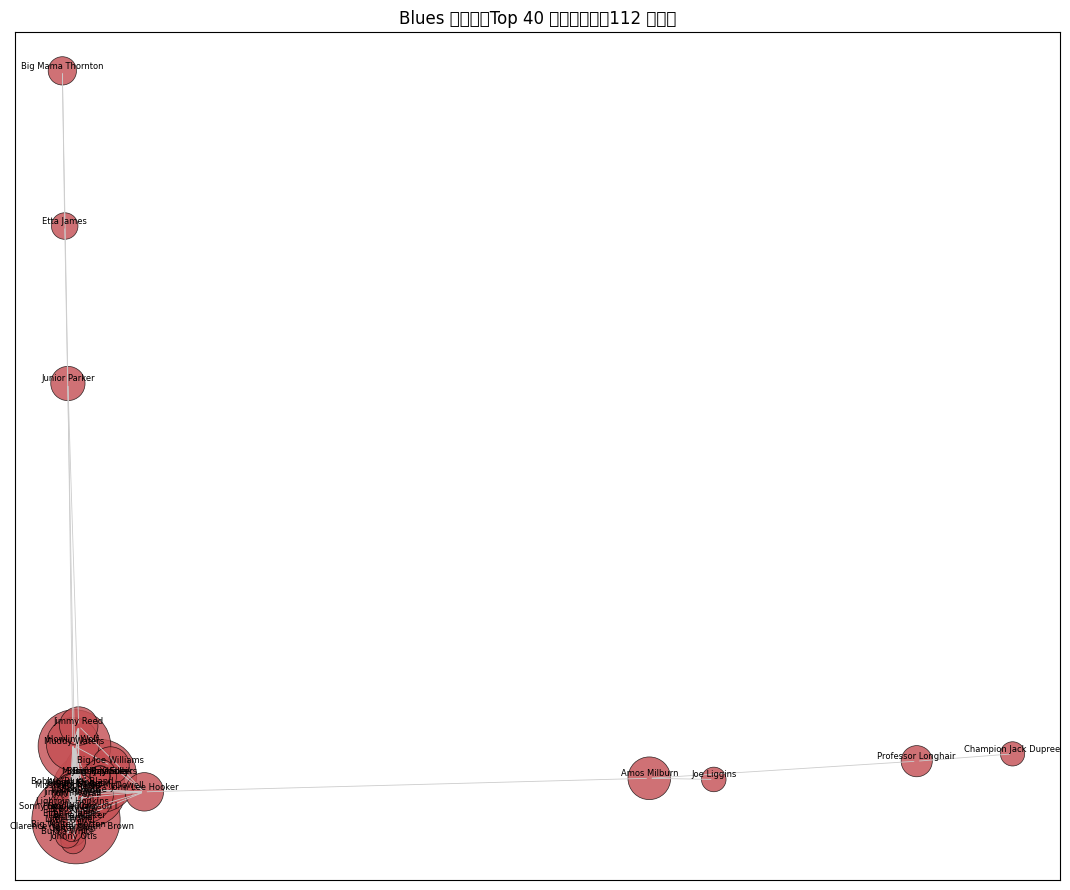

In [6]:
from sklearn.manifold import spectral_embedding

K = 40
sub_ids = df[df['genre'] == 'Blues'].sort_values('pagerank_source', ascending=False).head(K).index
sub_set = set(sub_ids)
mask = edges['influencer_id'].isin(sub_set) & edges['follower_id'].isin(sub_set)
sub_edges = edges[mask]

sub_idx = {nid: i for i, nid in enumerate(sub_ids)}
srow = sub_edges['influencer_id'].map(sub_idx).values
scol = sub_edges['follower_id'].map(sub_idx).values
A_sub = sp.csr_matrix((np.ones(len(sub_edges)), (srow, scol)), shape=(K, K))

pos = spectral_embedding(A_sub + A_sub.T, n_components=2, random_state=0)

fig, ax = plt.subplots(figsize=(11, 9))
for u, v in zip(srow, scol):
    ax.annotate('', xy=pos[v], xytext=pos[u],
                arrowprops=dict(arrowstyle='-', color='#cccccc', lw=0.6))
sizes = 40 + 4000 * (df.loc[sub_ids, 'pagerank_source'].values /
                     df.loc[sub_ids, 'pagerank_source'].values.max())
ax.scatter(pos[:, 0], pos[:, 1], s=sizes, c='#C44E52', alpha=0.8, edgecolors='black', lw=0.5)
for i, nid in enumerate(sub_ids):
    ax.text(pos[i, 0], pos[i, 1], name_map.get(nid, nid), fontsize=6, ha='center', va='bottom')
ax.set_title(f'Blues 子网络（Top {K} 影响力节点，{len(sub_edges)} 条边）')
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 解读

- **三个主指标回答不同问题**：出度回答「直接影响了谁」，反向 PageRank 回答「追随者在网络中处于什么位置（递归传导）」，`reach3` 回答「沿记录关系能覆盖多远」。
- **`reach3` 的 caveat**：数据只记录了关系，无法确认影响确实沿这三跳传播；它描述的是**潜在的结构覆盖**。
- **`DIG` vs `cross_genre_ratio`**：一个 Rock 艺术家有 100 位 Rock 追随者 + 1 位 Jazz 追随者，`DIG=2` 但 `cross_genre_ratio=1/101≈0.01`。前者讲覆盖广度，后者讲跨流派影响。
- 排名呈幂律（富者愈富）：顶级源头经过多层下游链路滚雪球式累积权重。